<h1><b> Problem Set 5 </b></h1>

<h2>Part A</h2>

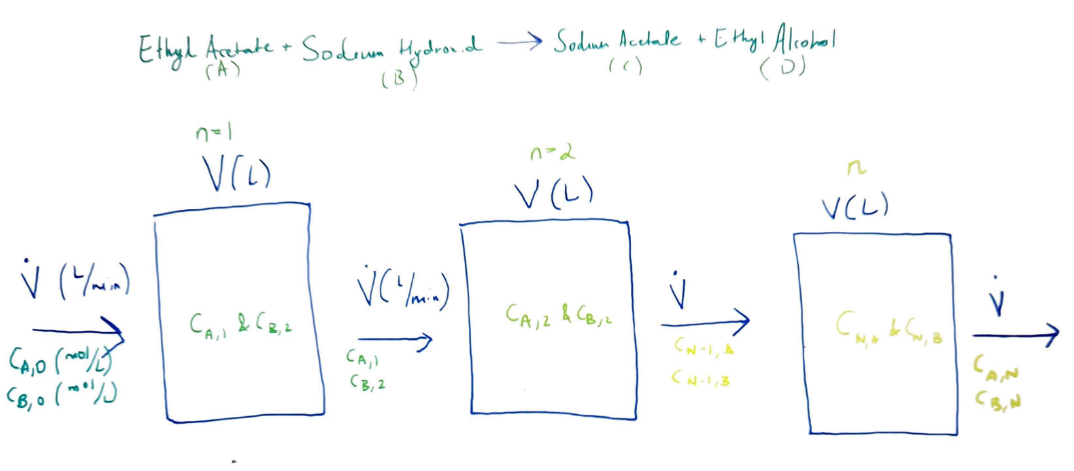

<h2> Part B </h2>

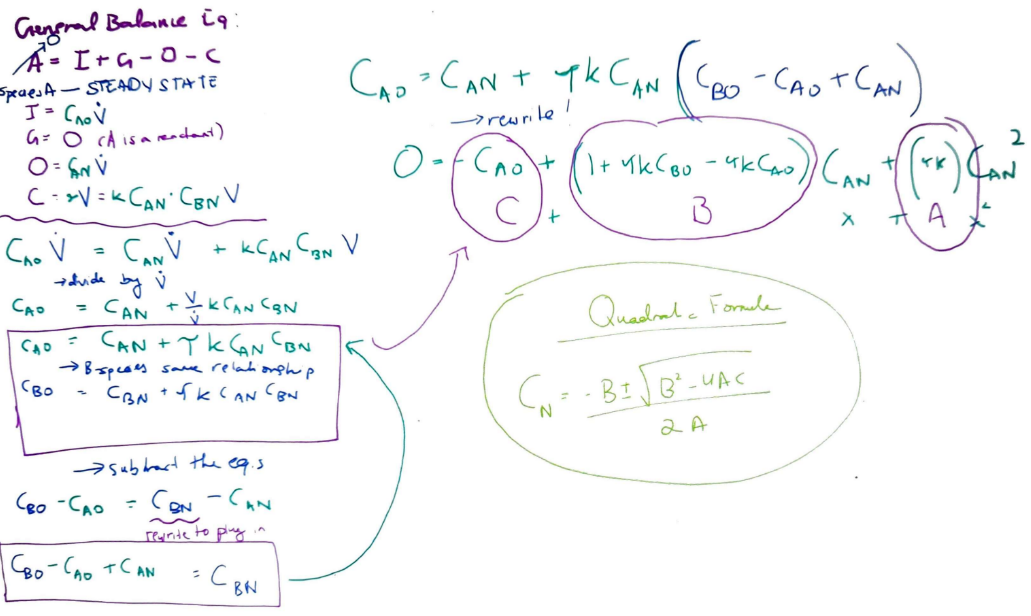

<h2> Part C </h2>

In [2]:
import numpy as np
Ca0 = 0.0567 # mol A/L
Cb0 = 0.1000 # mol B/L
tau = 2000/5000 #residence time
k = 36.2 
fc_targ = 0.8
fc = 0

def solvequad(canew):
    a = tau*k
    b = 1 + tau*k* Cb0 - tau*k*Ca0
    c = -canew
    roots1 = (-b + np.sqrt(b*b -4*a*c))/(2*a)
    return roots1

def conversionfrac (cai):
    return (Ca0-cai)/Ca0
i = 0 
cAN = Ca0
while (fc<fc_targ):
    i+=1
    cAN = solvequad(cAN)
    fc = conversionfrac(cAN)
   
print(f"The CSTR reaches above 80% conversion fraction at Reactor {i} with a conversion fraction of {fc*100:.3f}%")

The CSTR reaches above 80% conversion fraction at Reactor 3 with a conversion fraction of 84.777%


<h2> Part D </h2>

0.9999653207634106

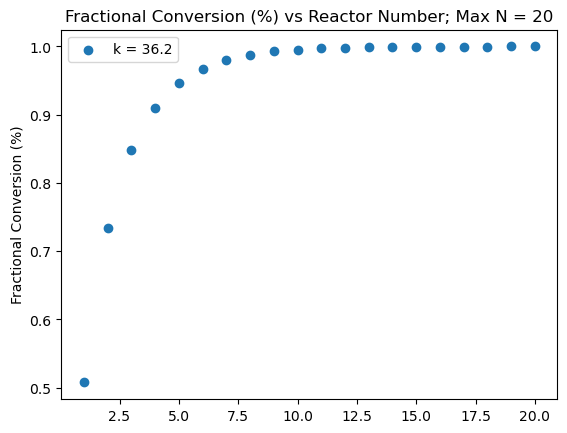

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def solvequad(k, cainit, cbinit,canew,v,flow):
    tau = v/flow
    a =  tau*k
    b = 1 + tau*k* cbinit - tau*k*cainit
    c = -canew
    roots1 = (-b + np.sqrt(b*b -4*a*c))/(2*a)
    return roots1

def conversionfrac (cai,caold):
    return (caold-cai)/caold


def reactor (k,v,flow,i, cainit, cbinit):
    reactors = []
    instantconc = []
    conversion = []

    start = 0 #index i
    caN = cainit
    instantconc.append(caN)

    for start in range (i):
        start+=1 
        reactors.append(start)
        caN = solvequad(k,cainit,cbinit,caN,v,flow)
        instantconc.append(caN)
        fc = conversionfrac(caN,cainit)
        conversion.append(fc)    
    plt.scatter(reactors, conversion, label = f"k = {k:.1f}")
    plt.ylabel("Fractional Conversion (%)")
    plt.title (f"Fractional Conversion (%) vs Reactor Number; Max N = {i}")
    plt.legend()

    return conversion[start-1] #returns the fractional conversion at the end of the series

Ca0 = 0.0567
Cb0 = 0.1000 
v = 2000
flow = 5000

#reactor(k,v,flow,3,Ca0, Cb0)
reactor(36.2,v,flow,20,Ca0, Cb0)




<h2> Part E </h2>
Your goal is to achieve a high conversion of species A, so that you can sell the
resulting products. Name 2 things you may implement to achieve higher conversion. What are
the drawbacks associated with each?

<h6> You can increase the temperature potentially, but a downside is that you may have to pay more. Fortunately, we will do a cost-benefit analysis to see how the extra expenditures for energy scales with profits. There is also the environmental drawback of greater emissions if our energy for heating comes from nonrenewable, CO2-positive sources. 

<h2> Part F </h2>
f). Show the structure of ethyl acetate. What is its boiling point? What is it’s heat
capacity in standard units of J/mol/K? Convert this to J/L/K. Be sure to indicate what your
source of information is wherever necessary
Boiling Point - 443.8 K

168.94 $ \frac{J}{mol*K}*\frac{1 mol}{88.11 g}= 1.917 \frac{J}{gK} $

1.917 $ \frac{J}{g*K}*\frac{902 g}{1 L}= 1729 \frac{J}{LK} $

Source: https://webbook.nist.gov/cgi/cbook.cgi?ID=C141786&Mask=6F

<h2> Part G </h2>
g). The reaction rate constant k typically varies exponentially with temperature, as
k = k0 exp(−Ea/RT ) where k0 is a constant, Ea is the activation energy for the reaction, R
is the universal gas constant, and T is temperature in Kelvin. Assuming an activation energy
of 50 kJ/mol, and assuming (this is purely hypothetical!) that the reaction rate k is 1 at a
1 temperature of 10 ◦C (corresponding to 283.15 K), calculate the reaction constant at the following
temperatures, all in ◦C: 20, 30, 40, 50, 70, 80. Use a semilogy plot to show how the reaction rate
varies as a function of temperature

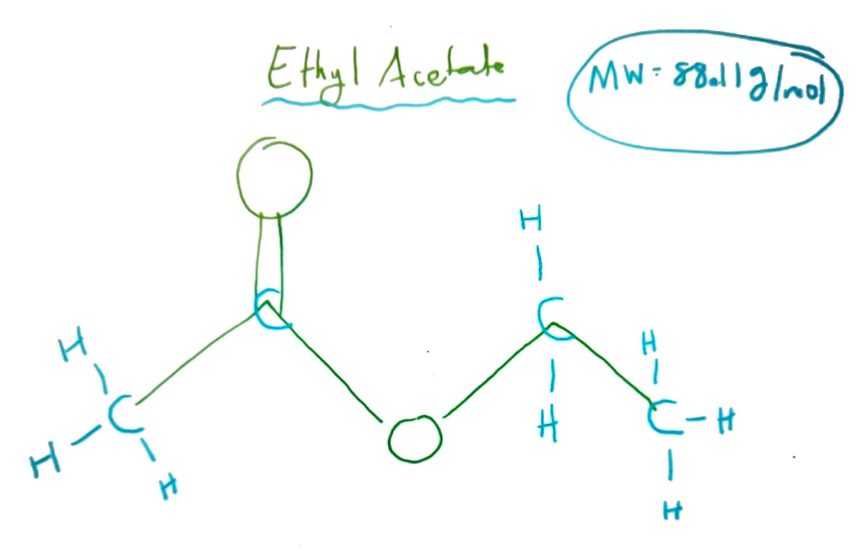

[283.15 293.15 303.15 313.15 323.15 333.15 343.15 353.15]
8


Text(0.5, 1.0, 'Reaction Constant vs Temperature (K)')

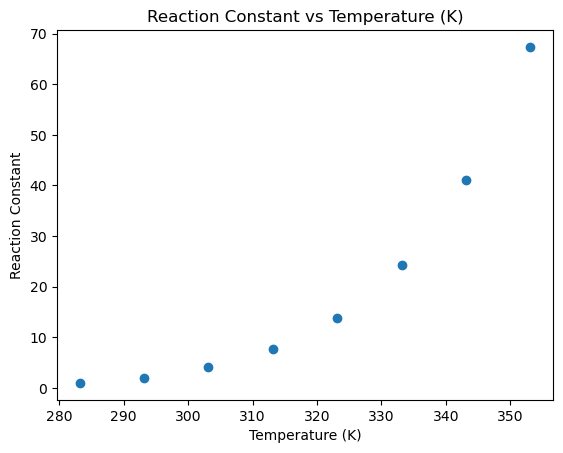

In [4]:
tinC =np.array([10,20,30,40,50,60,70,80])
tinK = tinC + 273.15
print(tinK)
Ea = 50 #kJ/mol
R = 0.008314 #kJ/mol*K
k10 = 1
k0 = 1.6756339758*10**9

kvals = []
print(len(tinK))
for i in range(len(tinK)):
    kvals.append(k0*np.e**(-Ea/(R*tinK[i])))

plt.scatter(tinK,kvals)
plt.xlabel("Temperature (K)")
plt.ylabel("Reaction Constant")
plt.title("Reaction Constant vs Temperature (K)")
#log plot below


Text(0.5, 1.0, 'ln(Reaction Constant) vs Temperature (K)')

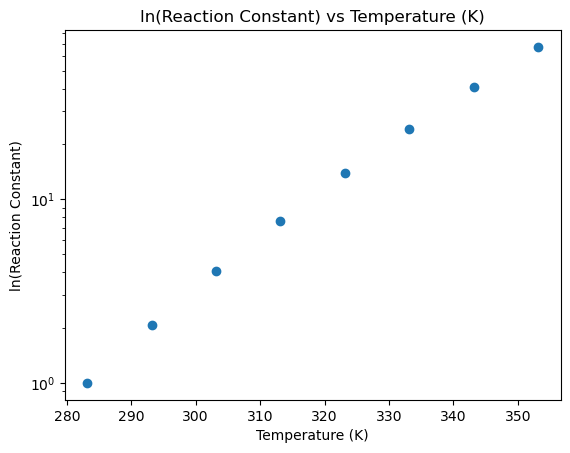

In [5]:
plt.figure(1)
plt.yscale("log")
plt.scatter(tinK,kvals)
plt.xlabel("Temperature (K)")
plt.ylabel("ln(Reaction Constant)")
plt.title("ln(Reaction Constant) vs Temperature (K)")

<h2> Part F </h2>
Let’s do a cost-benefit analysis. Assume that your company has a cascade containing
only N = 5 reactors, and you are unable to add reactors to your cascade. You want to examine
the impact of changing temperature on the potential profitability of your process. Calculate the
conversion you would have for the 6 reactor temperatures featured above. If the selling price
of your product is $x per L of reactant converted (we could use a mass basis of the individual
products and their selling prices, but let’s keep it simple!), and the cost of energy is $y per kWh,
use the heat capacity of ethylacetate to estimate the difference between the benefit and the cost
(i.e. the net gain or net loss) of operating at the 6 different temperatures indicated, relative to
the base case scenario of k=1 at 10 ◦C. For the current purposes, you may assume x is $0.50 and
y is $0.33. The final units of your cost-benefit analysis should be dollars per time, e..g $/min. Be
alert - re units! Some conversions may be necessary. Be explicit with your units and make sure
they cancel appropriately to yield the desired basis (i.e. dollars per unit time)

At temperature 283.15 K, the reaction constant is 1.000 and after 5 reactors, the fractional conversion is 16.860%. This means I will convert 0.000 more Liters of A and earn $0.000 more than base line 10 degrees Celsius in one minute. I will spend an additional $0.000 on energy.
The benefit: $0.000/min
 
At temperature 293.15 K, the reaction constant is 2.064 and after 5 reactors, the fractional conversion is 29.877%. This means I will convert 650.855 more Liters of A and earn $325.428 more than base line 10 degrees Celsius in one minute. I will spend an additional $2.152 on energy.
The benefit: $323.275/min
 
At temperature 303.15 K, the reaction constant is 4.060 and after 5 reactors, the fractional conversion is 46.574%. This means I will convert 1485.687 more Liters of A and earn $742.843 more than base line 10 degrees Celsius in one minute. I will spend an additional $6.710 on energy.
The benefit: $736.133/min
 
At temperature 313.15 K, the reaction constant is 7.650 and after 5 r

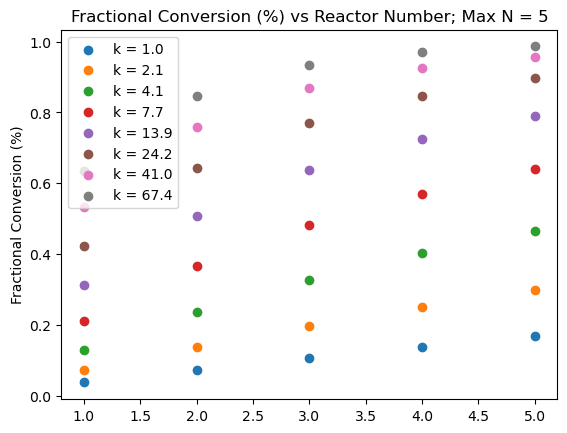

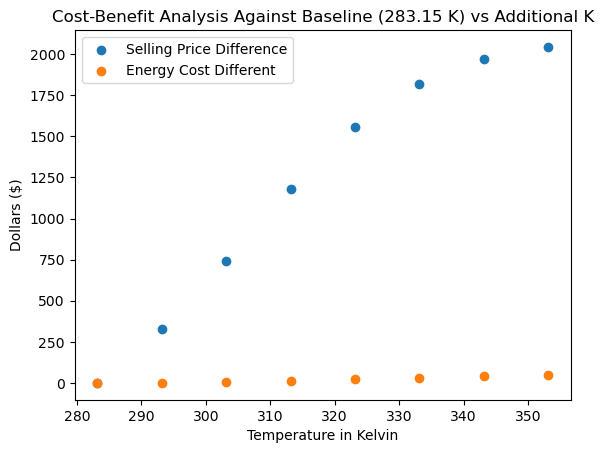

In [8]:
energy = 1729 # J/LK
energy = energy/3600000 #kwH/LK -  heating capacity
xprice = 0.50 #dollars per L reacted - selling price
y = 0.30 # dollars per kWh
outputA=[]

for i in range(len(kvals)):
    ffin = reactor(kvals[i], 2000,5000,5,Ca0,Cb0)
    outputA.append(ffin) 
    i+=1


lA = [x * 5000 for x in outputA] # fractional conversion * Liters/min   = liters of A convereted/min
revA = [x *  xprice - lA[0]*xprice for x in lA] # liters of A converted * price = selling cost
deltaPrice = [y*energy*(tinK[i]-tinK[0])*lA[i] for i in range(len(lA))]   #price per kwH * kwh needed to heat 1 Liter by 1 Kelvin * Number of extra Kelvin compared to base * liters = energy expenditure

profA = [ revA[i] - deltaPrice[i] for i in range(len(deltaPrice))]

for i in range(len(kvals)):
    print(f"At temperature {tinK[i]} K, the reaction constant is {kvals[i]:.3f} and after 5 reactors, the fractional conversion is {outputA[i]*100:.3f}%. This means I will convert {lA[i]-lA[0]:.3f} more Liters of A and earn ${revA[i]:.3f} more than base line 10 degrees Celsius in one minute. I will spend an additional ${deltaPrice[i]:.3f} on energy.")
    print(f"The benefit: ${profA[i]:.3f}/min")
    print(" ")

plt.figure(2)
plt.scatter(tinK, revA, label = f"Selling Price Difference")
plt.scatter(tinK, deltaPrice, label = f"Energy Cost Different")
plt.xlabel("Temperature in Kelvin")
plt.ylabel("Dollars ($)")
plt.title("Cost-Benefit Analysis Against Baseline (283.15 K) vs Additional K")
plt.legend()

<h2> Part I </h2>
What would the price of your product need to be relative to energy costs to incentivize
operation at higher temperatures? i.e. derive an expression (an inequality) that establishes this.
Describe to possible drawbacks to higher temperature operation. What is a reasonable cost per
kWh for commercial electricity consumption in the state of Pennsylvania? Be sure to indicate
what your source of information is re: electricity pricing

Selling Cost per L> Energy Cost per heating up 1 L. 
As show in our graph, this is always going to be the case when we changed the the temperature. The energy cost didn't change much because energy is relatively cheap. At $0.30 per kWh, we know it only takes a fraction of a kWh (1700 J/3,600,000 J/kWh) to heat up the liter by 1 degree Kelvin. So it comes down to a fraction of a cent per Liter. In contrast, we get a lot of money per Liter.

However, there are environmental concerns revolving greater energy usage. While it doesn't cost much, every kWh emits a bunch. Therefore, we need to be careful about minimizing energy harms as opposed to improving profits. 

A reasonable price is $0.206 cents per kWh in the Philadelphia area. 

Source: https://www.bls.gov/regions/mid-atlantic/news-release/averageenergyprices_philadelphia.htm#:~:text=Philadelphia%20area%20households%20paid%20an,per%20therm%20a%20year%20earlier.